# Pop-in Detection V2: Critical Point Extraction and Width Calculation

## 1. Definition of Metrics

In this version, we move beyond simple detection to quantify the physical characteristics of each pop-in event. We define two critical points and a magnitude metric for each event:

- **$P_1$ (Onset Point):** The $(F, D)$ coordinate just before the indentation curve "kinks". This represents the load and depth at which the material's elastic limit was exceeded or a dislocation avalanche was triggered.
- **$P_2$ (Recovery Point):** The $(F, D)$ coordinate where the slope of the curve returns to a stable, positive value. This represents the point where the material has rearranged its internal structure enough to support the applied load again.
- **Width ($\Delta D$):** Defined as $D(P_2) - D(P_1)$. This is the **displacement excursion**, representing the physical distance the indenter traveled during the burst. It is the most robust measure of a pop-in's magnitude.

## 2. Methodology

1. **Grouping:** Data is grouped by indent index.
2. **Loading Curve Isolation:** Analysis is restricted to the loading portion (up to $F_{max}$).
3. **Slope Calculation:** We calculate the instantaneous slope $dF/dD$.
4. **Thresholding:** We identify regions where the slope falls below `SLOPE_THRESHOLD` (e.g., 10 $\mu$N/$\mu$m).
5. **Event Grouping:** Consecutive points meeting the threshold are grouped into a single event.
6. **Point Extraction:** For each group, we pick the point immediately *before* the first threshold-crossing point as $P_1$ and the point immediately *after* the last threshold-crossing point as $P_2$.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Constants
SLOPE_THRESHOLD = 10  # uN / um
MIN_FORCE_uN = 25
EPSILON = 1e-9

def detect_popins(indent_df, slope_threshold=SLOPE_THRESHOLD, min_force=MIN_FORCE_uN):
    """
    Detects pop-ins and extracts P1, P2, Width, and Force_Drop for a single indent.
    """
    # 1. Isolate loading curve
    max_f_idx = indent_df['Force_uN'].idxmax()
    loading = indent_df.loc[:max_f_idx].copy()
    
    if len(loading) < 5: return []
    
    # 2. Calculate Slope dF/dD
    df = np.diff(loading['Force_uN'])
    dd = np.diff(loading['Displacement_um'])
    slope = df / (dd + EPSILON)
    
    # Pad to match index (slope[i] is between i and i+1, we'll associate it with index i+1)
    slope_padded = np.insert(slope, 0, np.inf)
    loading['Slope'] = slope_padded
    
    # 3. Identify candidates
    is_flat = (loading['Slope'] < slope_threshold) & (loading['Force_uN'] > min_force)
    
    # 4. Find runs
    events = []
    in_run = False
    run_start_idx = 0
    
    for i in range(1, len(loading)):
        if is_flat.iloc[i]:
            if not in_run:
                in_run = True
                run_start_idx = i
        else:
            if in_run:
                in_run = False
                p1_idx = run_start_idx - 1
                p2_idx = i
                
                if p1_idx < 0: continue
                
                p1 = loading.iloc[p1_idx]
                p2 = loading.iloc[p2_idx]
                
                # X-coordinate difference (P2 - P1)
                width = p2['Displacement_um'] - p1['Displacement_um']
                
                # Y-coordinate difference (P1 - P2)
                force_drop = p1['Force_uN'] - p2['Force_uN']
                
                events.append({
                    'P1': (p1['Force_uN'], p1['Displacement_um']),
                    'P2': (p2['Force_uN'], p2['Displacement_um']),
                    'Width': width,
                    'Force_Drop': force_drop,
                    'Force': p1['Force_uN']
                })
    return events

def plot_indent_with_popins(indent_df, events, indent_id, save_path=None):
    """
    Plots the Force-Displacement curve and marks pop-ins with arrows.
    """
    plt.figure(figsize=(8, 6))
    plt.plot(indent_df['Displacement_um'], indent_df['Force_uN'], 'b-', label='Indentation Curve')
    
    for i, ev in enumerate(events):
        f1, d1 = ev['P1']
        f2, d2 = ev['P2']
        w = ev['Width']
        fd = ev['Force_Drop']
        
        # Draw the pop-in arrow
        plt.annotate('', xy=(d2, f2), xytext=(d1, f1),
                     arrowprops=dict(arrowstyle='->', color='red', lw=1.5))
        
        # Label P1 and P2
        plt.text(d1, f1, f'P1', color='darkred', va='bottom', ha='right')
        plt.text(d2, f2, f'P2', color='darkred', va='top', ha='left')
        
        # Calculate midpoint for text placement
        mid_d = (d1 + d2) / 2
        mid_f = (f1 + f2) / 2
        
        # Print Width slightly above the midpoint (offset by +5 points)
        plt.annotate(f'w={w:.3f} um', xy=(mid_d, mid_f), xytext=(10, 5), 
                     textcoords='offset points', color='red', fontsize=9, va='bottom')
                     
        # Print Force Drop slightly below the midpoint (offset by -8 points)
        plt.annotate(f'ΔF={fd:.2f} uN', xy=(mid_d, mid_f), xytext=(10, -8), 
                     textcoords='offset points', color='blue', fontsize=9, va='top')

    plt.xlabel('Displacement (um)')
    plt.ylabel('Force (uN)')
    plt.title(f'Pop-in Detection for Indent #{indent_id}')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    
    if save_path:
        plt.savefig(save_path)
        plt.close()
    else:
        plt.show()

Loaded 387726 rows from dataset/nano.txt

--- Detailed Pop-in Results ---
Detected events in 25 unique indents.

Indentation #18:
  Number of pop-ins: 1
  Pop-in 1:
    P1 (Onset):    Disp=0.86968 um, Force=28.95853 uN
    P2 (Recovery): Disp=0.87454 um, Force=27.94359 uN
    Width:         0.00486 um
    Force Drop:    1.01494 uN
------------------------------
Indentation #26:
  Number of pop-ins: 1
  Pop-in 1:
    P1 (Onset):    Disp=1.21439 um, Force=12691.31028 uN
    P2 (Recovery): Disp=1.22108 um, Force=12749.57421 uN
    Width:         0.00669 um
    Force Drop:    -58.26393 uN
------------------------------
Indentation #63:
  Number of pop-ins: 1
  Pop-in 1:
    P1 (Onset):    Disp=0.82167 um, Force=329.16371 uN
    P2 (Recovery): Disp=0.82750 um, Force=326.17543 uN
    Width:         0.00583 um
    Force Drop:    2.98828 uN
------------------------------
Indentation #140:
  Number of pop-ins: 1
  Pop-in 1:
    P1 (Onset):    Disp=0.84370 um, Force=274.49846 uN
    P2 (Recovery

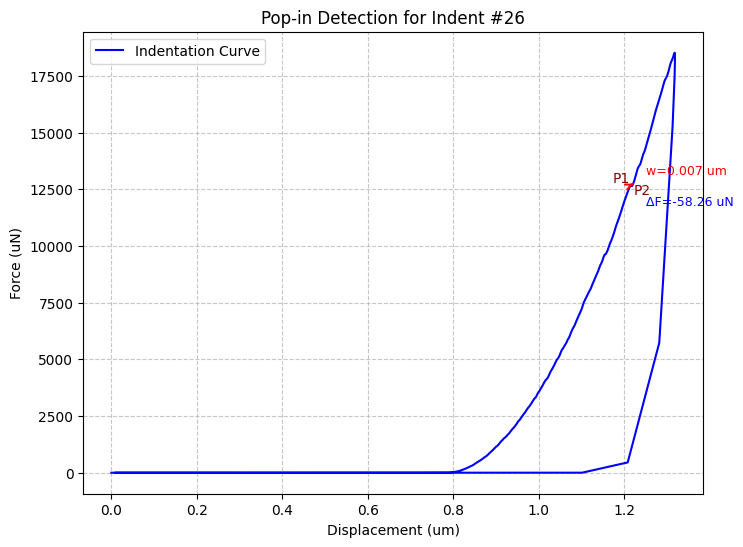

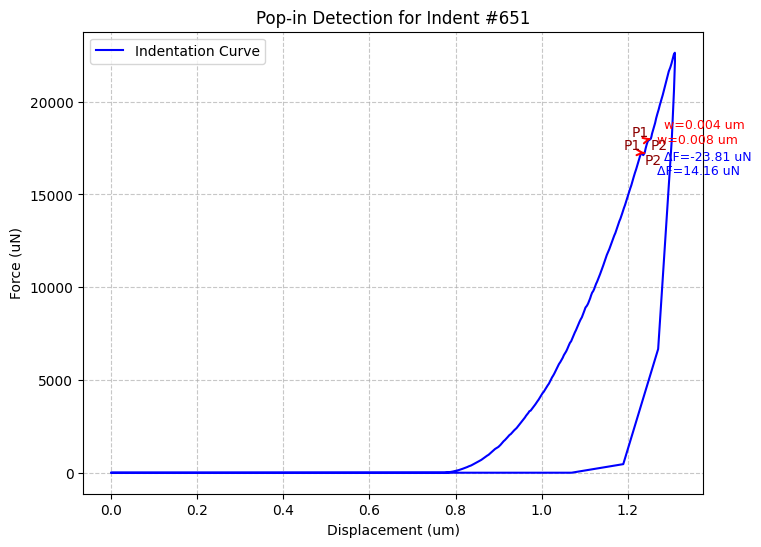

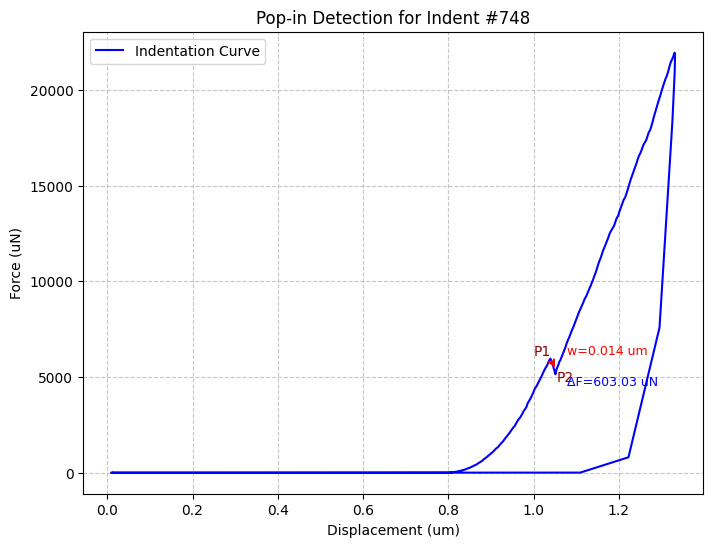

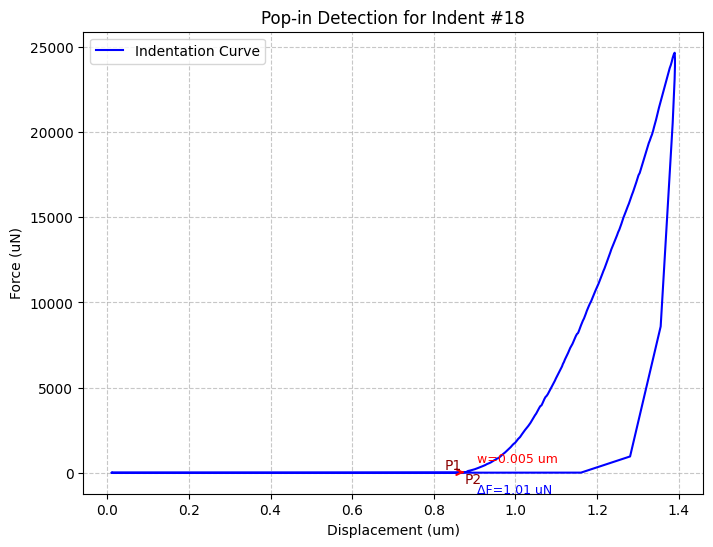

In [4]:
# 1. Load Data
data_path = 'dataset/nano.txt'
if os.path.exists(data_path):
    column_names = {
        0: 'Index',
        2: 'Displacement_um',
        5: 'PosX_um',
        6: 'PosY_um',
        10: 'Force_uN',
        29: 'Hardness_MPa',
        30: 'ReducedModulus_MPa'
    }
    df_raw = pd.read_csv(data_path, comment='/', sep='\s+', header=None)
    df = df_raw[column_names.keys()].rename(columns=column_names)
    df['Index'] = df['Index'].astype(int)
    df.dropna(inplace=True)
    df = df[(df['Force_uN'] >= 0) & (df['Displacement_um'] >= 0)]
    print(f"Loaded {len(df)} rows from {data_path}")
else:
    print("Error: dataset/nano.txt not found.")
    df = pd.DataFrame() 

# 2. Run Detection and Print Detailed Results
if not df.empty:
    grouped = df.groupby('Index')
    indent_results = {}
    
    for idx, group in grouped:
        events = detect_popins(group)
        if events:
            indent_results[idx] = events

    print(f"\n--- Detailed Pop-in Results ---")
    print(f"Detected events in {len(indent_results)} unique indents.\n")
    
    for idx, events in indent_results.items():
        print(f"Indentation #{idx}:")
        print(f"  Number of pop-ins: {len(events)}")
        for i, ev in enumerate(events):
            f1, d1 = ev['P1']
            f2, d2 = ev['P2']
            print(f"  Pop-in {i+1}:")
            print(f"    P1 (Onset):    Disp={d1:.5f} um, Force={f1:.5f} uN")
            print(f"    P2 (Recovery): Disp={d2:.5f} um, Force={f2:.5f} uN")
            print(f"    Width:         {ev['Width']:.5f} um")
            print(f"    Force Drop:    {ev['Force_Drop']:.5f} uN")
        print("-" * 30)

# 3. Sample Visualizations
sample_indices = [26, 651, 748, 18]
for idx in sample_indices:
    if idx in df['Index'].values:
        group = df[df['Index'] == idx]
        events = detect_popins(group)
        plot_indent_with_popins(group, events, idx)